In [3]:
import socket
from pyspark.sql import SparkSession

spark = SparkSession.builder.getOrCreate()
print("Running on:   ", socket.gethostname())
print("Spark master: ", spark.sparkContext.master)
print("Spark version:", spark.version)

Running on:    rainfall-dev-m
Spark master:  yarn
Spark version: 3.5.3


In [4]:
import time
from pyspark.sql import functions as F

start = time.time()
nums = spark.range(0, 50_000_000).withColumn("group", F.col("id") % 10)
result = nums.groupBy("group").agg(F.count("*").alias("n"), F.avg("id").alias("avg_id"))
result.orderBy("group").show()
print(f"Took {time.time() - start:.1f} s")

+-----+-------+-----------+
|group|      n|     avg_id|
+-----+-------+-----------+
|    0|5000000|2.4999995E7|
|    1|5000000|2.4999996E7|
|    2|5000000|2.4999997E7|
|    3|5000000|2.4999998E7|
|    4|5000000|2.4999999E7|
|    5|5000000|      2.5E7|
|    6|5000000|2.5000001E7|
|    7|5000000|2.5000002E7|
|    8|5000000|2.5000003E7|
|    9|5000000|2.5000004E7|
+-----+-------+-----------+

Took 2.0 s


In [5]:
!gcloud storage ls gs://dsa5208-rainfall-sixing-data/raw/

gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2017).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2018).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2019).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2020).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2021).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2022).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2023).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2024).csv


In [7]:
DATA = "gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore*.csv"

rain = spark.read.option("header", True).csv(DATA)
rain.printSchema()
rain.show(5, truncate=False)
print("Rows:", rain.count())

root
 |-- date: string (nullable = true)
 |-- timestamp: string (nullable = true)
 |-- update_timestamp: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_device_id: string (nullable = true)
 |-- location_longitude: string (nullable = true)
 |-- location_latitude: string (nullable = true)
 |-- reading_update_timestamp: string (nullable = true)
 |-- reading_value: string (nullable = true)
 |-- reading_type: string (nullable = true)
 |-- reading_unit: string (nullable = true)



+----------+-------------------------+-------------------------+----------+-------------------+-----------------+------------------+-----------------+-------------------------+-------------+-----------------------------+------------+
|date      |timestamp                |update_timestamp         |station_id|station_name       |station_device_id|location_longitude|location_latitude|reading_update_timestamp |reading_value|reading_type                 |reading_unit|
+----------+-------------------------+-------------------------+----------+-------------------+-----------------+------------------+-----------------+-------------------------+-------------+-----------------------------+------------+
|2017-01-01|2017-01-01T08:04:59+08:00|2017-01-01T08:13:31+08:00|S77       |Alexandra Road     |S77              |103.8125          |1.2937           |2017-01-01T08:13:31+08:00|0.0          |TB1 Rainfall 5 Minute Total F|mm          |
|2017-01-01|2017-01-01T08:04:59+08:00|2017-01-01T08:13:31+08:00|

Rows: 48538713


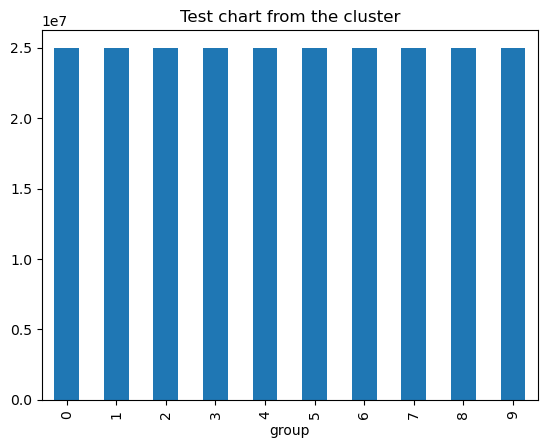

In [8]:
import matplotlib.pyplot as plt

pdf = result.orderBy("group").toPandas()
pdf.plot(x="group", y="avg_id", kind="bar", legend=False)
plt.title("Test chart from the cluster")
plt.show()